In [ ]:
# Colab does not have these two packages; the course's tensorflow container does.
%pip install tslearn icecream

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.4/374.4 kB 6.2 MB/s eta 0:00:00


In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"  # Keras 3 runs on TensorFlow, PyTorch or JAX. Set it before importing keras.
import keras
from keras import layers
from icecream import ic
import numpy as np
from tslearn.datasets import CachedDatasets
from tslearn.preprocessing import TimeSeriesScalerMeanVariance

# Generate synthetic data for person distance from home
n_ts, sz = 1000, 10  # Number of time series 1k and size is 10 timesteps

# Make 4 time-series features
# Scale the data
scaler1 = TimeSeriesScalerMeanVariance(mu=0., std=1.)
dataset_0 = np.abs(scaler1.fit_transform(np.random.rand(n_ts, sz, 4))) # we now have a population that stays near home
scaler2 = TimeSeriesScalerMeanVariance(mu=0.4, std=.8)
dataset_1 = np.abs(scaler2.fit_transform(np.random.rand(n_ts, sz, 4))) # we now have a population that ventures a bit farther from home

# Create labels
labels_0 = np.zeros(n_ts) # close to home people
labels_1 = np.ones(n_ts) # wanderers

# Combine data and labels

X_train = np.concatenate((dataset_0[:int(0.8*n_ts),             :,:], dataset_1[:int(0.8*n_ts),             :,:]), axis=0)
X_val   = np.concatenate((dataset_0[int(0.8*n_ts):int(0.9*n_ts),:,:], dataset_1[int(0.8*n_ts):int(0.9*n_ts),:,:]), axis=0)
X_test  = np.concatenate((dataset_0[int(0.9*n_ts):,             :,:], dataset_1[int(0.9*n_ts):,             :,:]), axis=0)

y_train = np.concatenate((labels_0[:int(0.8*n_ts)], labels_1[:int(0.8*n_ts)]), axis=0)
y_val   = np.concatenate((labels_0[int(0.8*n_ts):int(0.9*n_ts)], labels_1[int(0.8*n_ts):int(0.9*n_ts)]), axis=0)
y_test  = np.concatenate((labels_0[int(0.9*n_ts):], labels_1[int(0.9*n_ts):]), axis=0)

ic(X_train.shape, y_train.shape,X_val.shape, y_val.shape,X_test.shape, y_test.shape) # check the shape
print(X_train[0]) # check the first data point
print(y_train[0]) # check its label

cell1:34: RuntimeWarning: Failed to access the underlying source code for analysis. Was ic() invoked in a REPL (e.g. from the command line), a frozen application (e.g. packaged with PyInstaller), or did the underlying source code change during execution?
ic| (1600, 10, 4), (1600,), (200, 10, 4), (200,), (200, 10, 4), (200,)
[[9.53020120e-02 3.71309305e-01 4.91392187e-01 5.35046537e-01]
 [3.35690200e-01 5.04639891e-02 4.45572102e-02 9.23232336e-01]
 [1.52386265e+00 1.64791100e+00 1.10451872e+00 6.02259079e-01]
 [1.61525419e-01 1.65197665e+00 1.23391083e+00 2.45938326e+00]
 [1.72494992e+00 1.08606303e+00 1.06049351e+00 8.31752592e-01]
 [1.57536318e+00 8.82397201e-01 3.29659840e-02 4.55578024e-01]
 [1.38728756e+00 8.68198787e-02 9.99262111e-01 1.14559977e+00]
 [2.44563766e-03 1.45788442e+00 6.05995244e-01 4.29112631e-01]
 [2.23789701e-01 5.21933925e-01 1.40343499e+00 2.29205439e-01]
 [3.13218485e-01 2.26732969e-01 1.59778999e+00 4.06189715e-02]]
0.0


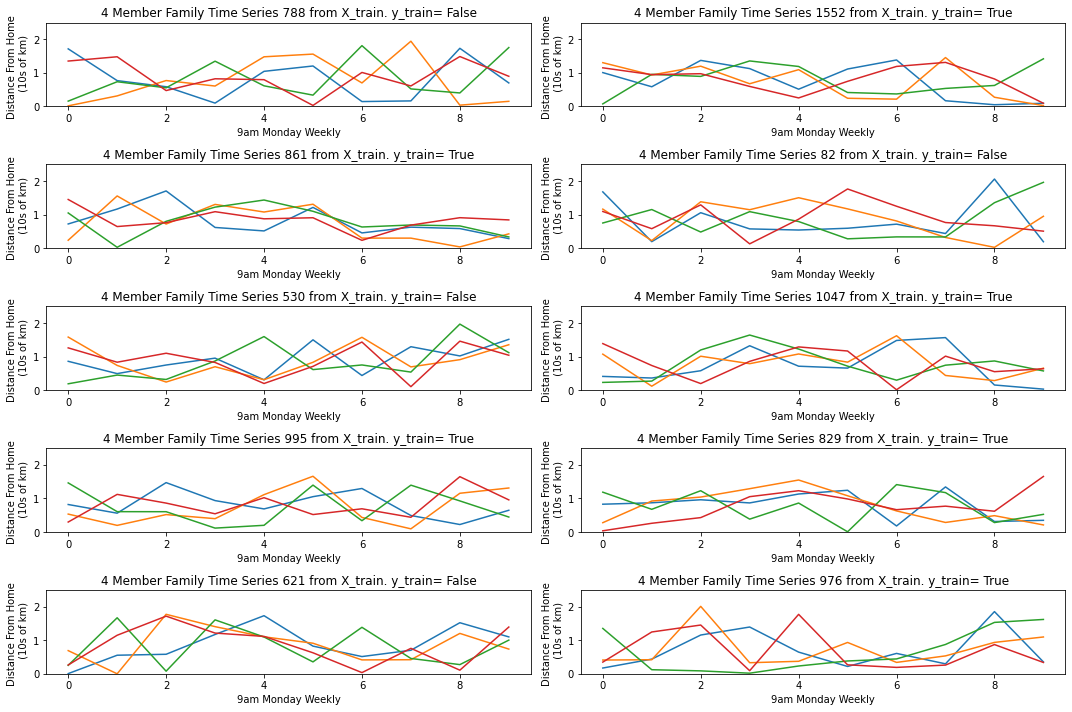

In [3]:
import matplotlib.pyplot as plt
import random

# X_train is 3D with shape (samples, time_steps, features)
# y_train is a 1D array

samps = X_train.shape[0] # Number of samples to plot
indices = random.sample(range(samps), 10)  # Select 10 random samples

# Create a single figure with multiple subplots
fig, axes = plt.subplots(5, 2, figsize=(15, 10))  # Adjust rows and columns as needed
axes = axes.flatten()  # Flatten to easily iterate

for ax, i in zip(axes, indices):
    ax.plot(X_train[i, :, :])  # Plotting the first feature of the time series
    ax.set_title(f"4 Member Family Time Series {i} from X_train. y_train= {1 == y_train[i]}")
    ax.set_xlabel("9am Monday Weekly")
    ax.set_ylabel("Distance From Home \n (10s of km)")
    ax.set_ylim(0, 2.5)  # Set y-axis range

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

In [4]:
import random

# make a generic generator
def datagen(samples,labels):
  while True:
    for i in random.sample(range(len(samples)),len(samples)):
      yield (samples[i][np.newaxis,:,:].astype(np.float32), np.array([labels[i]], dtype=np.float32))

# make generator instances
train_gen = datagen(X_train,y_train)
val_gen = datagen(X_val,y_val)
test_gen = datagen(X_test,y_test)
next(train_gen),next(train_gen),next(train_gen)

((array([[[0.4440029 , 0.93617904, 0.41896284, 2.0826879 ],
        [1.7573155 , 0.4424197 , 1.5937759 , 0.6670826 ],
        [1.5741192 , 0.56057644, 1.7673216 , 0.39145607],
        [0.17503351, 0.02206677, 0.26379168, 0.9702019 ],
        [0.8060366 , 1.7756265 , 0.02254372, 0.48847523],
        [1.3316077 , 0.9881011 , 1.339761  , 0.8304508 ],
        [0.9131331 , 0.6230606 , 0.00663201, 0.70828587],
        [0.37917686, 0.8867044 , 1.3175968 , 0.98182946],
        [0.80554307, 1.5326082 , 0.37184784, 1.2244451 ],
        [0.39604878, 0.9800871 , 0.64922476, 0.47927272]]], dtype=float32), array([0.], dtype=float32)), (array([[[6.7136461e-01, 8.3318317e-01, 2.4264808e-01, 1.0832806e+00],
        [1.5298470e+00, 9.6613169e-01, 2.9357442e-01, 1.5155733e+00],
        [7.8305638e-01, 1.2323135e+00, 3.0362573e-01, 1.1343968e+00],
        [1.0635489e+00, 1.0359235e-01, 1.1485705e+00, 2.7995872e-01],
        [8.6940479e-01, 2.0316060e-01, 1.5246515e+00, 7.3408586e-01],
        [2.6808152e-

In [5]:
# Data for LSTM input (samples, timesteps, features)
#X = X.reshape(X.shape[0], X.shape[1], X.shape[2])

# Define the LSTM model
model = keras.Sequential()
model.add(keras.Input(shape=(X_train.shape[1], X_train.shape[2])))
model.add(layers.LSTM(50, activation='relu', return_sequences=True))
model.add(layers.LSTM(10, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(train_gen, epochs=15, validation_data=val_gen, steps_per_epoch=100, validation_steps=25)
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)
print('Loss:', loss)
print('Accuracy:', accuracy)

# Make predictions
predictions = model.predict(X_test)
#[((p[0]>.5)==(y_t==1)) for p,y_t in zip(predictions,y_test)]

Epoch 1/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 0.4800 - loss: 0.6937 - val_accuracy: 0.6400 - val_loss: 0.6582
Epoch 2/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.4200 - loss: 0.6995 - val_accuracy: 0.3200 - val_loss: 0.6956
Epoch 3/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.5200 - loss: 0.6913 - val_accuracy: 0.6800 - val_loss: 0.6755
Epoch 4/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.5700 - loss: 0.7103 - val_accuracy: 0.4800 - val_loss: 0.6845
Epoch 5/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.5300 - loss: 0.6903 - val_accuracy: 0.6000 - val_loss: 0.6788
Epoch 6/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - accuracy: 0.6900 - loss: 0.6832 - val_accuracy: 0.4400 - val_loss: 0.6824
Epoch 7/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - accuracy: 0.5900 - loss: 0.6376 - val_accuracy: 0.6000 - val_loss: 0.6276
Epoch 8/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - accuracy: 0.6200 - loss: 0.6782 - val_accu

In [6]:
from sklearn.metrics import classification_report

# Convert probabilities to class labels (0 or 1)
predicted_labels = (predictions > 0.5).astype(int)

# Generate the classification report
report = classification_report(y_test, predicted_labels)

print(report)

              precision    recall  f1-score   support

         0.0       0.96      0.87      0.91       100
         1.0       0.88      0.96      0.92       100

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.91       200
weighted avg       0.92      0.92      0.91       200

